# Qiskit Fall Fest 2026: Day 0 installation check

Run this notebook top to bottom. If every cell runs and the last cell prints **All checks passed**, your environment is ready for Day 1.

No IBM Quantum account is needed. Everything runs on a local simulator.

## 1. Install

In [ ]:
%pip install --upgrade 'qiskit[visualization]>=2.5.0' qiskit-aer matplotlib

After the install finishes, **restart the kernel** (Kernel > Restart), then run the cells below.

## 2. Check Python and imports

In [1]:
import sys

print(f"Python {sys.version_info[0]}.{sys.version_info[1]}", "(OK)" if sys.version_info[:2] >= (3, 10) else "(3.10 or later recommended)")

import qiskit
import matplotlib.pyplot as plt
from qiskit.circuit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler, EstimatorV2 as Estimator

print("Qiskit version:", qiskit.__version__)

Python 3.14 (OK)
Qiskit version: 2.5.2


## 3. Build a circuit
A Hadamard gate puts one qubit into the state $H|0\rangle = (|0\rangle + |1\rangle)/\sqrt{2}$. Measuring it gives 0 or 1 with probability 50% each. The observable $Z$ then has expectation value $\langle Z \rangle = 0$.

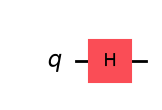

In [2]:
qc = QuantumCircuit(1)
qc.h(0)

observable = SparsePauliOp("Z")

qc.draw("mpl")

## 4. Transpile for the simulator

In [3]:
backend = AerSimulator()
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_meas = qc.copy()
qc_meas.measure_all()
isa_qc_meas = pm.run(qc_meas)   # for Sampler (needs measurements)

isa_qc = pm.run(qc)             # for Estimator (no measurements)
isa_observable = observable.apply_layout(isa_qc.layout)

print("Transpiled OK")

Transpiled OK


## 5. Run Sampler and Estimator

In [4]:
sampler = Sampler()
counts = sampler.run([isa_qc_meas], shots=1000).result()[0].data.meas.get_counts()
print("Sampler counts:", counts)

estimator = Estimator()
res = estimator.run([(isa_qc, isa_observable)]).result()[0]
exp_val = float(res.data.evs)
print(f"Estimator <Z> = {exp_val:.4f}")

Sampler counts: {'0': 499, '1': 501}
Estimator <Z> = 0.0000


## 6. Plot

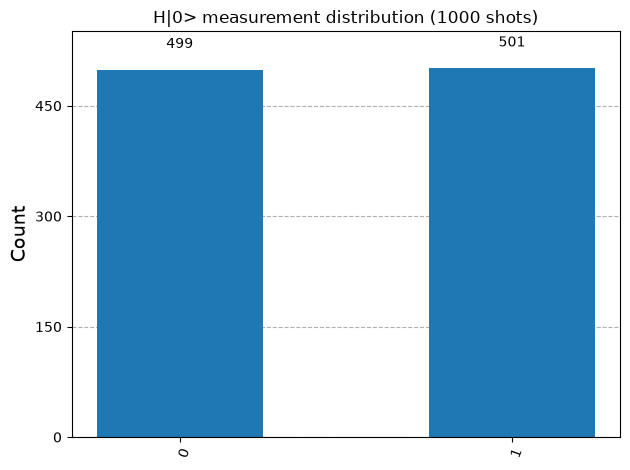

In [5]:
plot_histogram(counts, title="H|0> measurement distribution (1000 shots)")

## 7. Final check

In [6]:
p0 = counts.get("0", 0) / 1000
assert 0.40 < p0 < 0.60, f"Counts look wrong: {counts}"
assert abs(exp_val) < 0.2, f"<Z> should be close to 0, got {exp_val}"
print("All checks passed. You are ready for Day 1!")

All checks passed. You are ready for Day 1!
